In [3]:
### Tiền xử lý dữ liệu

In [4]:
#Làm sạch dữ liệu

In [5]:
import pandas as pd

df1 = pd.read_csv("comments.csv")
df2 = pd.read_csv("commentss.csv")

df = pd.concat([df1, df2], ignore_index=True)

In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 168063 entries, 0 to 168062
Data columns (total 7 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   id           141281 non-null  float64
 1   comment_id   141281 non-null  float64
 2   title        168059 non-null  object 
 3   thank_count  168063 non-null  int64  
 4   customer_id  168063 non-null  int64  
 5   rating       168063 non-null  int64  
 6   content      120345 non-null  object 
dtypes: float64(2), int64(3), object(2)
memory usage: 9.0+ MB


In [7]:
#Xóa các dữ liệu bị trùng lặp
df = df.drop_duplicates(subset=['customer_id','content'], keep='first')

#Xóa các cột không cần thiết như id, thank_count, customer_id
df = df.drop(columns=['id'])
df = df.drop(columns=['thank_count'])
df = df.drop(columns=['customer_id'])

# Xoá những dòng bị thiếu ở cột 'content' (quan trọng để xử lý text)
df = df.dropna(subset=['content'])

df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 88777 entries, 2 to 168054
Data columns (total 4 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   comment_id  80562 non-null  float64
 1   title       88774 non-null  object 
 2   rating      88777 non-null  int64  
 3   content     88777 non-null  object 
dtypes: float64(1), int64(1), object(2)
memory usage: 3.4+ MB


In [8]:
#Load các danh sách emoji, stopword, từ viết tắt để chuẩn bị làm sạch dữ liệu

In [9]:
import re

#Danh sách các emoji cần xóa
emoji_pattern = re.compile(
        "["
        u"\U0001F600-\U0001F64F"  # Mặt cười, cảm xúc
        u"\U0001F300-\U0001F5FF"  # Biểu tượng thiên nhiên, đối tượng
        u"\U0001F680-\U0001F6FF"  # Biểu tượng giao thông
        u"\U0001F1E0-\U0001F1FF"  # Cờ quốc gia
        u"\U00002702-\U000027B0"  # Ký hiệu dạng hình
        u"\U000024C2-\U0001F251"  # Ký hiệu đóng khung
        u"\U0001F926-\U0001F937"  # Hành động, cử chỉ
        u"\U00010000-\U0010FFFF" # Các ký tự bổ sung
        u"\u200d"                 # Nối ký tự (zero width joiner)
        u"\u2640-\u2642"          # Ký hiệu giới tính
        u"\u2600-\u2B55"          # Biểu tượng đa dạng khác
        u"\u23cf"                 # Biểu tượng đẩy đĩa
        u"\u23e9"                 # Tua nhanh
        u"\u231a"                 # Đồng hồ
        u"\u3030"                 # Dấu ngoằn ngoèo
        u"\ufe0f"                 # Bộ chọn kiểu hiển thị
        "]+", flags=re.UNICODE
)

#Load danh sách các stop word
vietnamese_stopwords = set(open('vietnamese-stopwords.txt', encoding='utf-8').read().splitlines())

#Load danh sách các từ viết tắt hay sử dụng trong tiếng Việt
short_word_dict = {
    "ko": "không",
    "kg": "không",
    "khong": "không",
    "k": "không",
    "kh": "không",
    "cx": "cũng",
    "mik": "mình",
    "mn": "mọi người",
    "bt": "bình thường",
    "nv": "nhân viên",
    "sp": "sản phẩm",
    "đc": "được",
    "dc": "được",
    "đk": "điều khoản",
    "đt": "điện thoại",
    "j": "gì",
    "vs": "với",
    "hok": "không",
    "lun": "luôn",
    "z": "gì",
    "zậy": "gì vậy",
    "thik": "thích",
    "hum": "hôm",
    "wa": "qua",
    "m": "mình",
    "mk": "mình",
    "bn": "bạn",
    "ok": "ổn",
    "t":  "tôi",
    "e":   "em",
    "a":   "anh",
    "bc":  "bác",
    "ad":  "admin",
    "mod": "moderator",
    "ib":  "inbox",
    "inb": "inbox",
    "stt": "status",
    "tl":  "trả lời",
    "tks": "cảm ơn",
    "thx": "cảm ơn",
    "thank": "cảm ơn",
    "cn":  "công nghệ",
    "tech": "công nghệ",
    "sv":  "sinh viên",
    "nt":  "nhắn tin",
    "tn":  "tin nhắn",
    "mxh": "mạng xã hội",
    "cf":  "cà phê",
    "bp":  "bộ phận",
    "pk":  "phụ kiện",
    "tb":  "thông báo",
    "hp":  "hạnh phúc",
    "cv":  "công việc",
    "ck":  "chuyển khoản",
    "vk":  "vợ",
    "ckho": "chồng",
    "sk":  "sức khỏe",
    "gw":  "gửi",
    "vl":  "vãi l*n",
    "vkl": "vãi cả l*n",
    "sml": "sấp mặt luôn"
}

In [10]:
#Trực quan hóa stop word

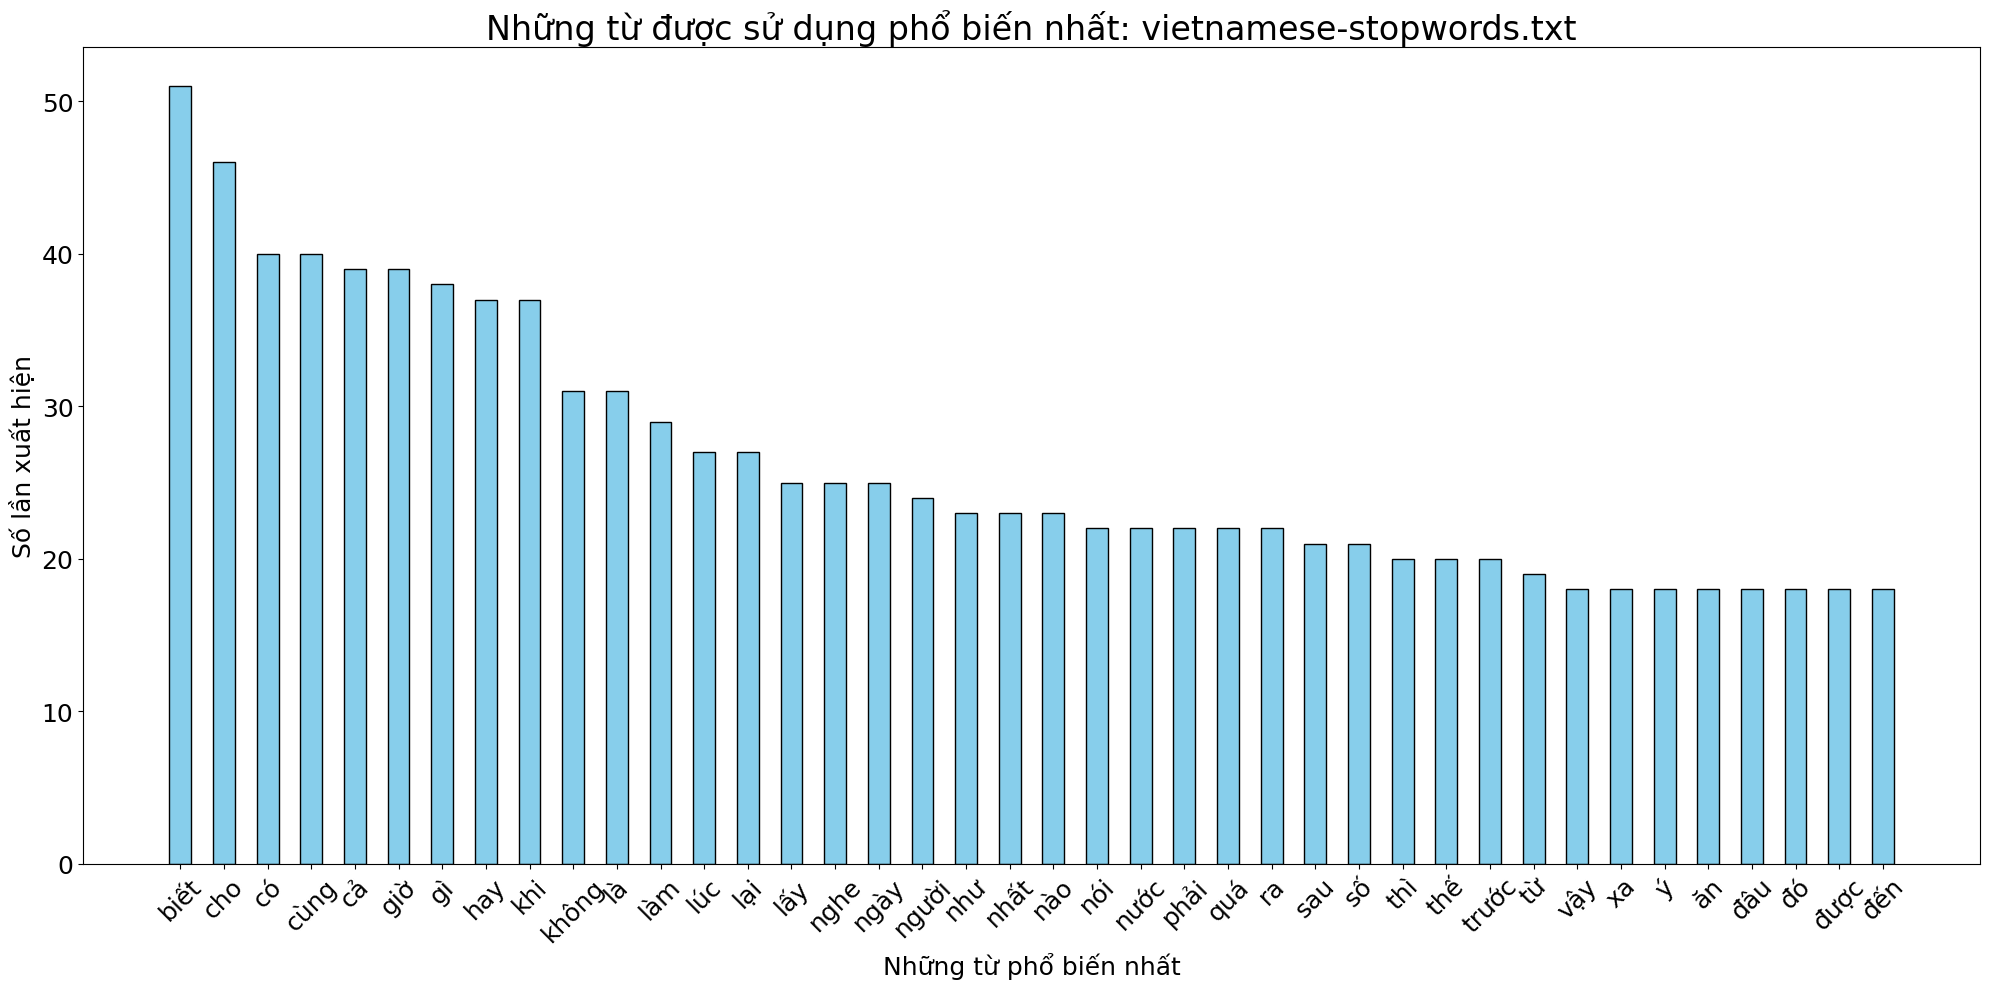

In [11]:
import numpy as np
from matplotlib import pyplot as plt

def plotWordFrequency(vietnamese_file):
    # Đọc file stopword
    with open(vietnamese_file, 'r', encoding='utf-8') as f:
        words = [x for y in [l.strip().split() for l in f.readlines()] for x in y]

    # Đếm số lần xuất hiện của từ và xắp xếp chúng theo thứ tự
    data = sorted([(w, words.count(w)) for w in set(words)], key=lambda x: x[1], reverse=True)[:40]

    most_words = [x[0] for x in data]
    times_used = [x[1] for x in data]

    # Vẽ biểu đồ cột
    plt.figure(figsize=(20, 10))
    plt.bar(x=sorted(most_words), height=times_used, color='skyblue', edgecolor='black', width=.5)
    plt.xticks(rotation=45, fontsize=18)
    plt.yticks(fontsize=18)
    plt.xlabel('Những từ phổ biến nhất', fontsize=18)
    plt.ylabel('Số lần xuất hiện', fontsize=18)
    plt.title('Những từ được sử dụng phổ biến nhất: %s' % vietnamese_file.split('/')[-1], fontsize=24)
    plt.tight_layout()
    plt.show()
    
plotWordFrequency('vietnamese-stopwords.txt')

In [12]:
#Hàm làm sạch dữ liệu

In [13]:
from underthesea import word_tokenize # Bộ ngữ nghĩa
from underthesea import text_normalize #Chuẩn hóa văn bản

def clean_data(text):
    #Loại bỏ NaN / non-string
    if not isinstance(text, str):
        return ""
    
    #Chuyển chữ thường
    text = text.lower()
    
    #Rút gọn ký tự lặp (okkkkk → ok)
    text = re.sub(r"(.)\1{2,}", r"\1", text)
    
    #Xóa emoji
    text = emoji_pattern.sub("", text)
    
    #Xóa ký tự đặc biệt (chỉ giữ chữ và số)
    text = re.sub(r"[^\w\s]", " ", text)
    
    #Chuẩn hóa dấu câu, gạch nối, v.v.
    text = text_normalize(text)
    
    #Chuẩn hóa từ viết tắt
    words = text.split()
    words = [short_word_dict.get(w, w) for w in words]
    text = " ".join(words)
    
    #Tách từ bằng Underthesea
    text = word_tokenize(text, format="text")
    
    return text

In [14]:
###Chuẩn hóa dữ liệu

In [15]:
#Chuẩn hóa cột content
df['clean_content'] = df['content'].map(lambda text: clean_data(text))

#Chuẩn hóa cột title
df['title'] = df['title'].map(lambda text: clean_data(text))
df['title'] = df['title'].str.replace('_', ' ')
#Kiểm tra
df.head(5)

,comment_id,title,rating,content,clean_content
2,NaN,cực kì hài lòng,5,"Sách nhà Giver đợt này lạ, sách viết về tài ch...",sách nhà giver đợt này lạ_sách viết về tài_chí...
3,NaN,cực kì hài lòng,5,"Vừa nhận sách là lên cmt liền, sách gì dễ thươ...",vừa nhận sách là lên cmt liền sách gì dễ_thươn...
4,NaN,cực kì hài lòng,5,"mình rất thích quyển sách này, chủ để tài chín...",mình rất thích quyển sách này chủ để tài_chính...
5,NaN,bình thường,3,"Nội dung cũng bình thường, không tung hô quá n...",nội_dung cũng bình_thường không tung hô quá nh...
6,NaN,cực kì hài lòng,5,Tiki giao nhanh. Nội dung sách cũng rất hay,tiki giao nhanh nội_dung sách cũng rất hay


In [16]:
###Cân bằng mẫu

In [17]:
##Cân bằng mẫu với 2 nhãn 

In [18]:
#Gộp thành 2 nhãn

In [19]:
import numpy as np

# Nếu rating ≥4 → tích cực, ngược lại → tiêu cực
df['title'] = np.where(
    df['rating'] >= 4,
    'cực kỳ hài lòng',
    'không hài lòng'
)

print(df['title'].value_counts())

title
cực kỳ hài lòng    78079
không hài lòng     10698
Name: count, dtype: int64


In [20]:
#Trực quan dữ liệu 2 nhãn

C:\Users\PC\AppData\Local\Temp\ipykernel_16596\2078117514.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(counts), y=list(words),
C:\Users\PC\AppData\Local\Temp\ipykernel_16596\2078117514.py:64: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=list(counts), y=list(words),


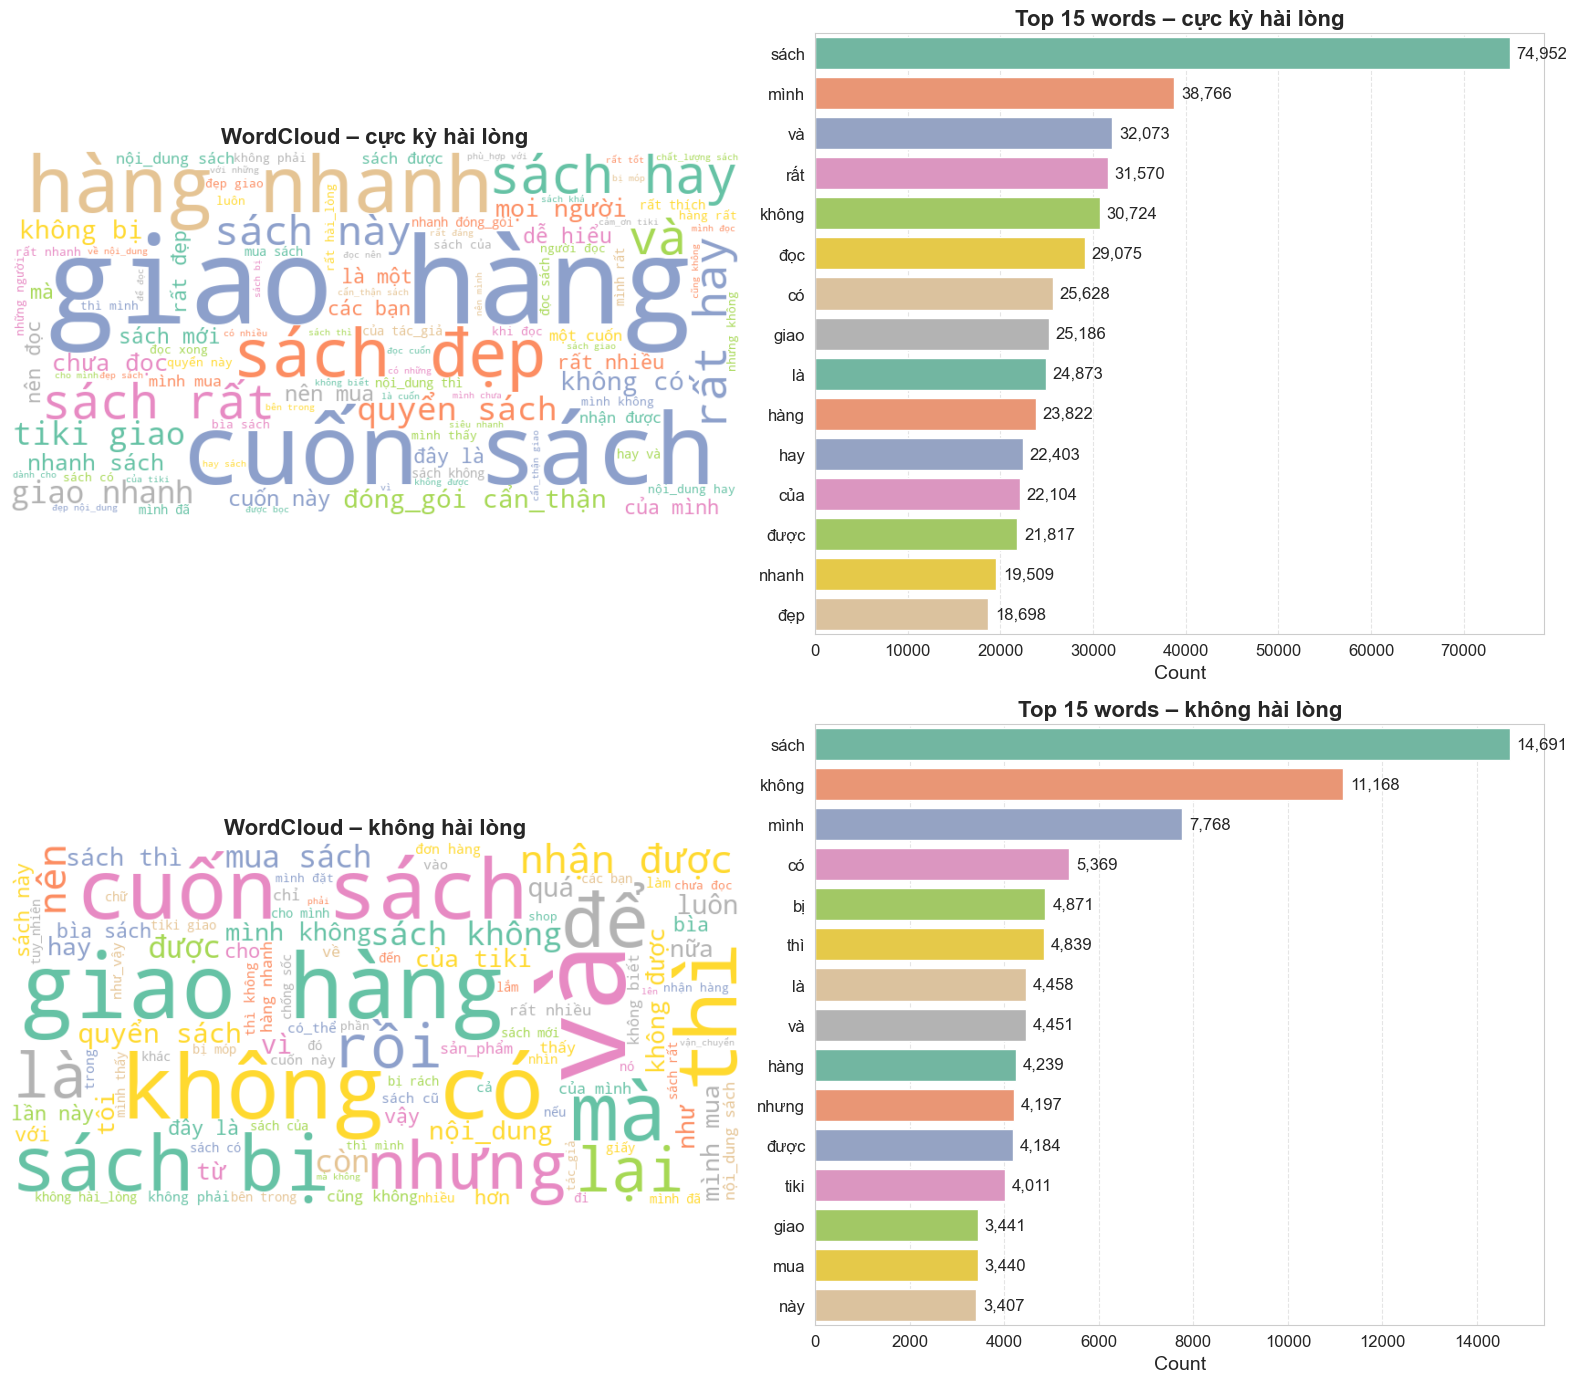

In [21]:
import nltk
import matplotlib.pyplot as plt
import seaborn as sns
from wordcloud import WordCloud

sns.set_style("whitegrid")
plt.rcParams.update({
    "font.size": 12,
    "axes.titlesize": 16,
    "axes.titleweight": "bold",
    "axes.labelsize": 14,
    "xtick.labelsize": 12,
    "ytick.labelsize": 12,
})

def compare_wordcloud_and_barchart(
    df,
    text_col="clean_content",
    label_col="title",
    labels=("cực kỳ hài lòng", "không hài lòng"),
    top_n=15,
    wc_max_words=100
):
    import nltk
    import matplotlib.pyplot as plt
    import seaborn as sns
    from wordcloud import WordCloud

    sns.set_style("whitegrid")
    plt.rcParams.update({"font.size": 12})

    #Chuẩn bị dữ liệu
    groups = {}
    for lbl in labels:
        tokens = [
            tok for txt in df[df[label_col]==lbl][text_col].dropna()
            for tok in txt.split() if tok.strip()
        ]
        groups[lbl] = {"tokens": tokens, "freq": nltk.FreqDist(tokens)}

    #Vẽ
    fig, axes = plt.subplots(2, 2, figsize=(16, 14))
    axes = axes.flatten()

    for i, lbl in enumerate(labels):
        #WordCloud với colormap tên "Set2"
        corpus = " ".join(groups[lbl]["tokens"])
        wc = WordCloud(
            max_words=wc_max_words,
            background_color="white",
            colormap="Set2",
            width=800, height=400
        ).generate(corpus)

        ax_wc = axes[i*2]
        ax_wc.imshow(wc, interpolation="bilinear")
        ax_wc.axis("off")
        ax_wc.set_title(f"WordCloud – {lbl}")

        #Bar chart
        most_common = groups[lbl]["freq"].most_common(top_n)
        words, counts = zip(*most_common)
        ax_bar = axes[i*2+1]
        sns.barplot(x=list(counts), y=list(words),
                    palette="Set2", ax=ax_bar)
        ax_bar.set_title(f"Top {top_n} words – {lbl}")
        ax_bar.set_xlabel("Count")
        ax_bar.grid(axis="x", linestyle="--", alpha=0.5)
        for j, cnt in enumerate(counts):
            ax_bar.text(cnt + max(counts)*0.01, j, f"{cnt:,}", va="center")

    plt.tight_layout()
    plt.show()

#Gọi hàm
compare_wordcloud_and_barchart(
    df,
    text_col="clean_content",
    label_col="title",
    labels=("cực kỳ hài lòng", "không hài lòng"),
    top_n=15,
    wc_max_words=100
)

In [22]:
#Chia đều tập dữ liệu

In [23]:
import pandas as pd

#Phân bổ lại nhãn sao cho cân bằng
df_cuc_ky_hai_long = df[df['title'] == 'cực kỳ hài lòng'].sample(
    n=df[df['title']=='không hài lòng'].shape[0],  #Số lượng tương đương nhóm 'không hài lòng'
    replace=False,
    random_state=42
)

df_khong_hai_long = df[df['title'] == 'không hài lòng']

#Nối lại và xáo trộn
df_balanced_2_label = pd.concat(
    [df_cuc_ky_hai_long, df_khong_hai_long],
    axis=0
).sample(frac=1, random_state=42).reset_index(drop=True)

#Kiểm tra cân bằng
print(df_balanced_2_label['title'].value_counts())

title
cực kỳ hài lòng    10698
không hài lòng     10698
Name: count, dtype: int64


In [24]:
#Chia tập dữ liệu thành train và test với tỷ lệ 70-30

In [25]:
from sklearn.model_selection import train_test_split

X = df_balanced_2_label['clean_content']
y = df_balanced_2_label['title']

train_sentences, test_sentences, train_labels, test_labels = train_test_split(
    X,
    y,
    test_size=0.3,
    random_state=42,
    stratify=y              
)

print(f"Train size: {len(train_sentences)}  —  Test size: {len(test_sentences)}")
print(train_labels.value_counts(), "\n", test_labels.value_counts())

Train size: 14977  —  Test size: 6419
title
không hài lòng     7489
cực kỳ hài lòng    7488
Name: count, dtype: int64 
 title
cực kỳ hài lòng    3210
không hài lòng     3209
Name: count, dtype: int64


In [27]:
import pandas as pd
from sklearn.model_selection import train_test_split
from transformers import AutoTokenizer

#Khởi tạo Tokenizer
tokenizer = AutoTokenizer.from_pretrained("vinai/phobert-base")

#Tokenize dữ liệu
train_encodings = tokenizer(train_sentences.tolist(), truncation=True, padding=True, max_length=128)
test_encodings = tokenizer(test_sentences.tolist(), truncation=True, padding=True, max_length=128)

print("Đã tokenize xong dữ liệu!")
print(f"Số lượng mẫu huấn luyện: {len(train_sentences)}")
print(f"Số lượng mẫu kiểm định: {len(test_sentences)}")

Đã tokenize xong dữ liệu!
Số lượng mẫu huấn luyện: 14977
Số lượng mẫu kiểm định: 6419


In [36]:
import torch

class CommentDataset(torch.utils.data.Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: torch.tensor(val[idx]) for key, val in self.encodings.items()}
        item['labels'] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels)
        
train_labels_numeric = train_labels.map({'không hài lòng': 0, 'cực kỳ hài lòng': 1})
test_labels_numeric = test_labels.map({'không hài lòng': 0, 'cực kỳ hài lòng': 1})

# Tạo Dataset từ các encodings và nhãn đã chia ở trên
train_dataset = CommentDataset(train_encodings, train_labels_numeric.tolist())
test_dataset  = CommentDataset(test_encodings, test_labels_numeric.tolist())

print("Đã tạo xong Dataset cho PyTorch:")
print(f"Số mẫu huấn luyện: {len(train_dataset)}")
print(f"Số mẫu kiểm định : {len(test_dataset)}")

Đã tạo xong Dataset cho PyTorch:
Số mẫu huấn luyện: 14977
Số mẫu kiểm định : 6419


In [38]:
from transformers import AutoModelForSequenceClassification, Trainer, TrainingArguments

# Tải mô hình PhoBERT với một lớp phân loại
model = AutoModelForSequenceClassification.from_pretrained("vinai/phobert-base", num_labels=2)

# Thiết lập các đối số huấn luyện
training_args = TrainingArguments(
    output_dir='./results',
    num_train_epochs=3,
    per_device_train_batch_size=8,
    per_device_eval_batch_size=16,
    warmup_steps=500,
    weight_decay=0.01,
    logging_dir='./logs',
    logging_steps=10,
    eval_strategy="epoch",
    save_strategy="epoch",
    load_best_model_at_end=True,
)

# Khởi tạo Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=train_dataset,
    eval_dataset=test_dataset
)

# Huấn luyện mô hình
print("\nBắt đầu quá trình huấn luyện PhoBERT...")
trainer.train()
print("Huấn luyện hoàn tất!")

# Đánh giá mô hình
eval_results = trainer.evaluate()
print("\nKết quả đánh giá trên tập kiểm định:")
print(eval_results)

Some weights of RobertaForSequenceClassification were not initialized from the model checkpoint at vinai/phobert-base and are newly initialized: ['classifier.dense.bias', 'classifier.dense.weight', 'classifier.out_proj.bias', 'classifier.out_proj.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.



Bắt đầu quá trình huấn luyện PhoBERT...


C:\Users\PC\anaconda3\envs\underthesea_env\lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Epoch,Training Loss,Validation Loss
1,0.364100,0.305430
2,0.356800,0.307481
3,0.270900,0.330285


C:\Users\PC\anaconda3\envs\underthesea_env\lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)
C:\Users\PC\anaconda3\envs\underthesea_env\lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)


Huấn luyện hoàn tất!


C:\Users\PC\anaconda3\envs\underthesea_env\lib\site-packages\torch\utils\data\dataloader.py:665: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  warnings.warn(warn_msg)



Kết quả đánh giá trên tập kiểm định:
{'eval_loss': 0.3054295480251312, 'eval_runtime': 468.8423, 'eval_samples_per_second': 13.691, 'eval_steps_per_second': 0.857, 'epoch': 3.0}


In [40]:
#Lưu model và tokenizer
model_save_path = "phobert_finetuned_2_nhan"
tokenizer_save_path = "phobert_tokenizer_2_nhan"

trainer.save_model(model_save_path)
tokenizer.save_pretrained(tokenizer_save_path)

print(f"\nĐã lưu thành công model vào thư mục: {model_save_path}")
print(f"Đã lưu thành công tokenizer vào thư mục: {tokenizer_save_path}")


Đã lưu thành công model vào thư mục: phobert_finetuned_2_nhan
Đã lưu thành công tokenizer vào thư mục: phobert_tokenizer_2_nhan


In [62]:
from transformers import pipeline

model_save_path = "./phobert_finetuned_2_nhan"
tokenizer_save_path = "./phobert_tokenizer_2_nhan"

# Tải pipeline phân loại văn bản với model đã lưu
print("Đang tải pipeline...")
classifier = pipeline("sentiment-analysis", model=model_save_path, tokenizer=tokenizer_save_path)
print("Tải pipeline thành công!")

# Ví dụ dự đoán
new_comments = [
    "Cuốn sách này thật tệ, tôi thật sự chán ghét khi đọc cuốn sách này",
    "Mình rất hài lòng về cuốn sách này",
    "Chất lượng của sách quá tệ, không như quảng cáo"
]

# Dự đoán
results = classifier(new_comments)

# In kết quả
print("\n--- KẾT QUẢ DỰ ĐOÁN ---")
for comment, result in zip(new_comments, results):
    # Lấy nhãn và điểm số từ kết quả dự đoán của model
    predicted_label = result['label']
    confidence_score = result['score'] * 100
    human_readable_label = "cực kỳ hài lòng" if predicted_label == 'LABEL_1' else "không hài lòng"
    print(f"\nBình luận: '{comment}'")
    print(f"  -> Nhãn dự đoán: {human_readable_label} (Độ chính xác: {confidence_score:.2f}%)")

Device set to use cpu


Đang tải pipeline...
Tải pipeline thành công!

--- KẾT QUẢ DỰ ĐOÁN ---

Bình luận: 'Cuốn sách này thật tệ, tôi thật sự chán ghét khi đọc cuốn sách này'
  -> Nhãn dự đoán: không hài lòng (Độ chính xác: 92.94%)

Bình luận: 'Mình rất hài lòng về cuốn sách này'
  -> Nhãn dự đoán: cực kỳ hài lòng (Độ chính xác: 88.69%)

Bình luận: 'Chất lượng của sách quá tệ, không như quảng cáo'
  -> Nhãn dự đoán: không hài lòng (Độ chính xác: 93.42%)
